In [274]:
#importing all needed libraries:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder , LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
from sklearn.svm import SVC 
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc, classification_report
import time  



In [275]:
#reading the dataset file
df = pd.read_csv("D:\\Users\\aaa\\Desktop\\heart.csv")
df

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat,1
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat,1
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat,1
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat,1


In [276]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [277]:
numericals=["Age" , "RestingBP" , "Cholesterol" , "MaxHR" , "Oldpeak"]
categoricals=["Sex" , "ChestPainType" , "FastingBS" , "RestingECG" , "ExerciseAngina" , "ST_Slope"]
target=["HeartDisease"]

In [278]:
missing_values_per_feature=df.isnull().sum()
print(f"missing values per feature is:{missing_values_per_feature}")

missing values per feature is:Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


In [279]:
total_number_of_missing_values = df.isnull().sum().sum()
print(f"Total number of missing values in the entire dataset: {total_number_of_missing_values}")

Total number of missing values in the entire dataset: 0


In [280]:
#although the number of missing values were ,I wrote this part in case we adjust new data to our dataset.
cat=df[categoricals]
num=df[numericals]
tar=df[target]
imputed_cat=SimpleImputer(strategy="most_frequent")
imputed_num=SimpleImputer(strategy="median")  #using median instead of mean for better results
cat=imputed_cat.fit_transform(cat)
num=imputed_num.fit_transform(num)


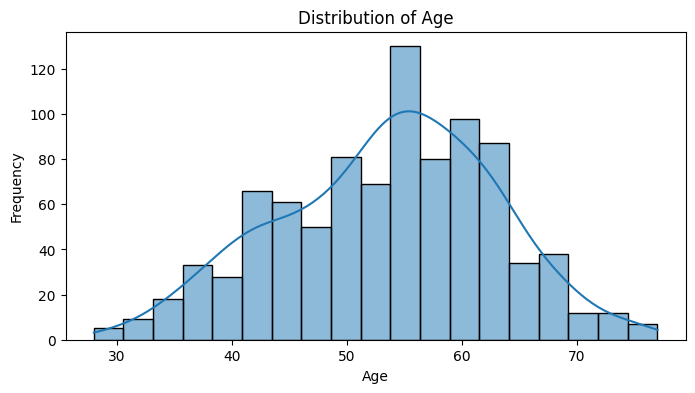

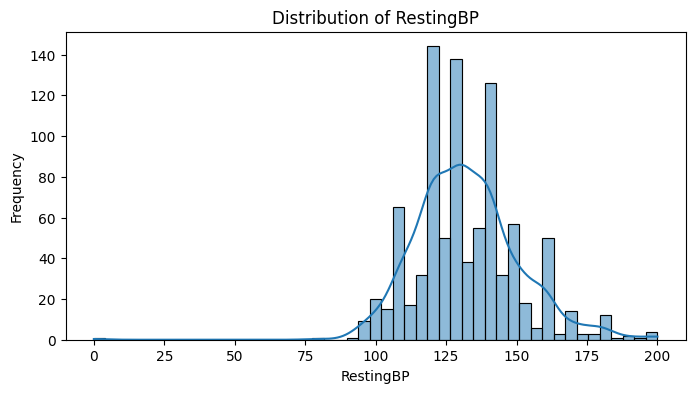

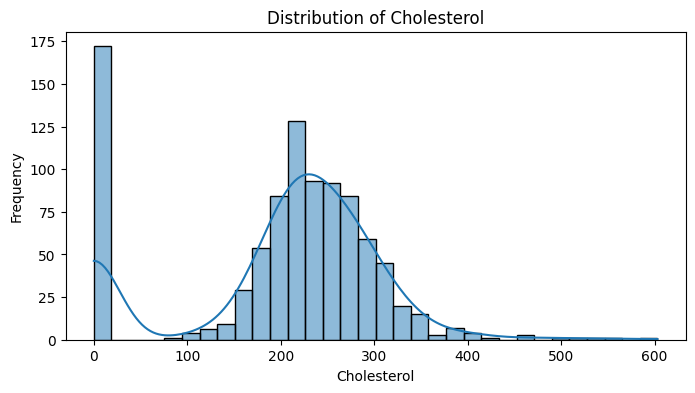

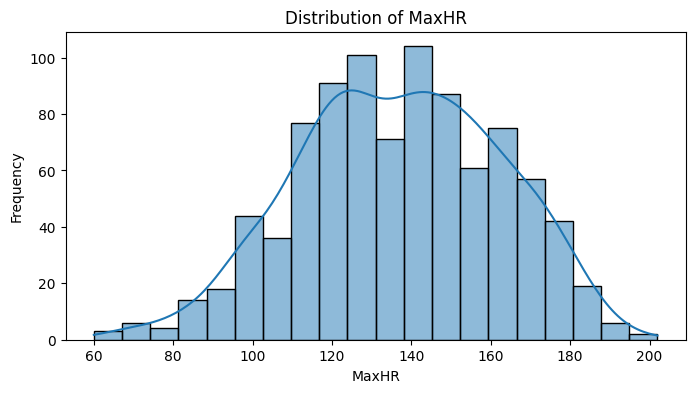

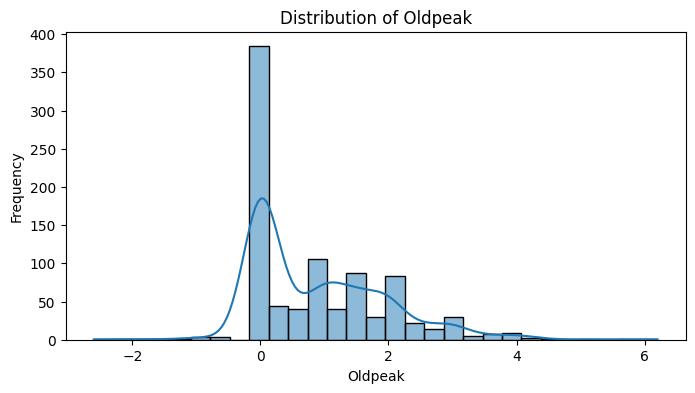

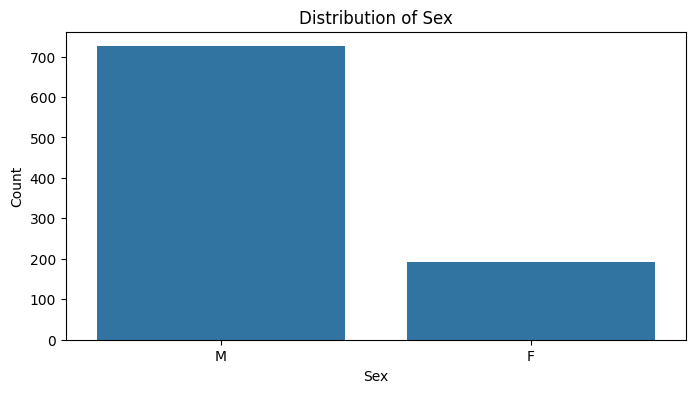

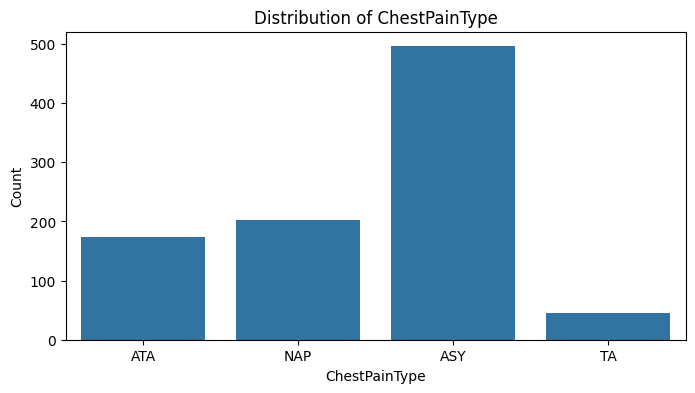

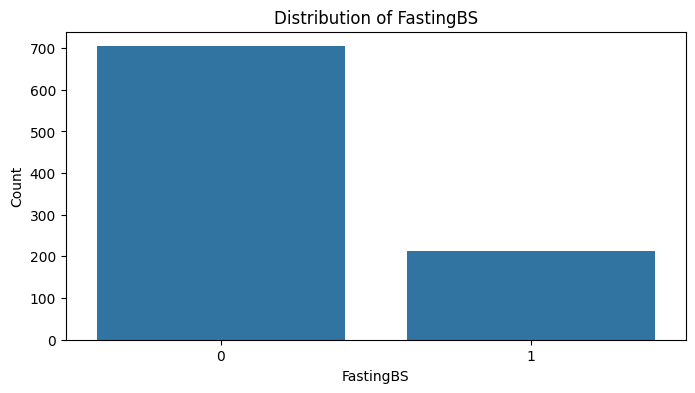

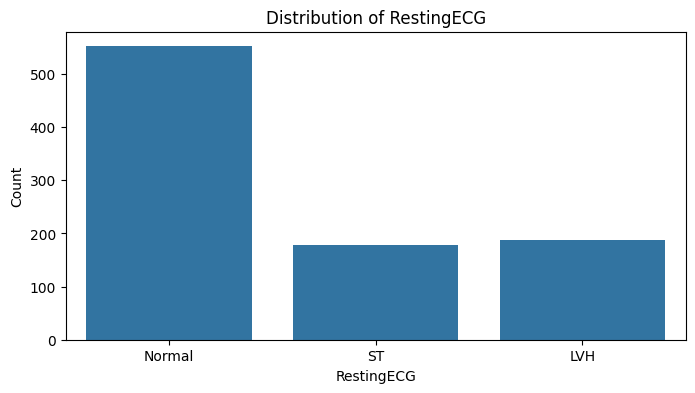

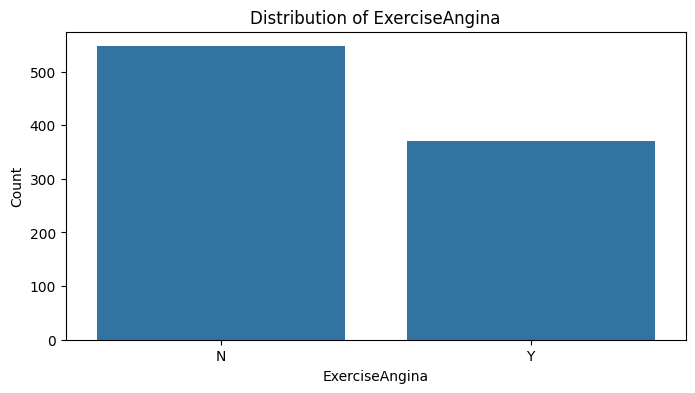

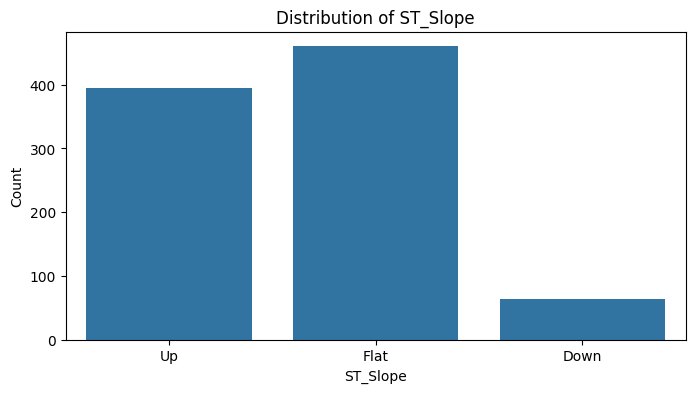

In [281]:

for column in numericals:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[column], kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.show()

for column in categoricals:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=df[column])
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Count')
    plt.show()



In [282]:
def apply_le(df, columns):
    LE = LabelEncoder()
    df_copy = df.copy()  
    for col in columns:
        df_copy[col] = LE.fit_transform(df_copy[col])
    return df_copy

def apply_ohe(df, columns):
    OHE = OneHotEncoder(drop="if_binary", sparse_output=False)
    cat_encoded = OHE.fit_transform(df[columns])
    cat_columns = OHE.get_feature_names_out(columns)
    df_cat_encoded = pd.DataFrame(cat_encoded, columns=cat_columns)
    df_copy = df.drop(columns=columns)  
    return pd.concat([df_copy, df_cat_encoded], axis=1)  

df_transformed = df.copy()
df_transformed = apply_le(df_transformed, ['Sex', 'ExerciseAngina'])
df_transformed = apply_ohe(df_transformed, ['ChestPainType', 'RestingECG', 'ST_Slope'])

#changing the position of the HeartDisease
target_column = 'HeartDisease'  
if target_column in df_transformed.columns:
    heart_disease = df_transformed.pop(target_column) 
    df_transformed[target_column] = heart_disease  

df_transformed = df_transformed.sort_values(by=target_column, ascending=False)

print(df_transformed.head())



     Age  Sex  RestingBP  Cholesterol  FastingBS  MaxHR  ExerciseAngina  \
409   53    1        160            0          1    122               1   
254   55    1        145          248          0     96               1   
410   62    1        150            0          1     78               0   
901   58    0        170          225          1    146               1   
411   54    1        180            0          1    150               0   

     Oldpeak  ChestPainType_ASY  ChestPainType_ATA  ChestPainType_NAP  \
409      0.0                0.0                0.0                1.0   
254      2.0                1.0                0.0                0.0   
410      2.0                1.0                0.0                0.0   
901      2.8                1.0                0.0                0.0   
411      1.5                1.0                0.0                0.0   

     ChestPainType_TA  RestingECG_LVH  RestingECG_Normal  RestingECG_ST  \
409               0.0             1

In [283]:
new_numericals=['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR',
       'ExerciseAngina', 'Oldpeak', 'HeartDisease', 'ChestPainType_ASY',
       'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_LVH', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Down',
       'ST_Slope_Flat', 'ST_Slope_Up']

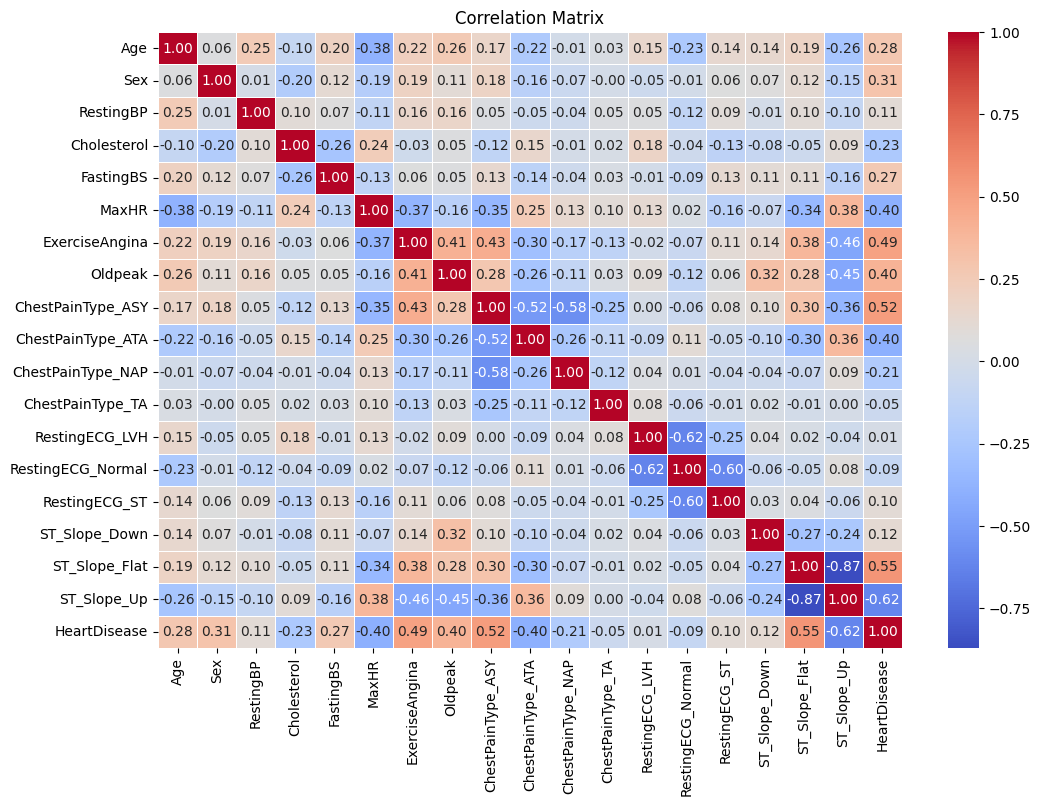

In [284]:
corr_matrix = df_transformed.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Correlation Matrix")
plt.show()


In [285]:
X = df_transformed.drop(columns=['HeartDisease'])
y = df_transformed['HeartDisease']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
print(X_scaled_df.head())


        Age       Sex  RestingBP  Cholesterol  FastingBS     MaxHR  \
0 -0.054192  0.515952   1.491752    -1.818435   1.813758 -0.581981   
1  0.157954  0.515952   0.681120     0.450040  -0.551341 -1.603734   
2  0.900464  0.515952   0.951331    -1.818435   1.813758 -2.311102   
3  0.476173 -1.938163   2.032174     0.239657   1.813758  0.361175   
4  0.051881  0.515952   2.572596    -1.818435   1.813758  0.518368   

   ExerciseAngina   Oldpeak  ChestPainType_ASY  ChestPainType_ATA  \
0        1.214246 -0.832432          -1.084138          -0.481887   
1        1.214246  1.043759           0.922392          -0.481887   
2       -0.823556  1.043759           0.922392          -0.481887   
3        1.214246  1.794236           0.922392          -0.481887   
4       -0.823556  0.574711           0.922392          -0.481887   

   ChestPainType_NAP  ChestPainType_TA  RestingECG_LVH  RestingECG_Normal  \
0           1.876744         -0.229679        1.970528          -1.228087   
1         

Decision Tree Model accuracy: 0.8206521739130435

Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.81      0.80        80
           1       0.85      0.83      0.84       104

    accuracy                           0.82       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.82      0.82      0.82       184


Confusion Matrix:
[[65 15]
 [18 86]]


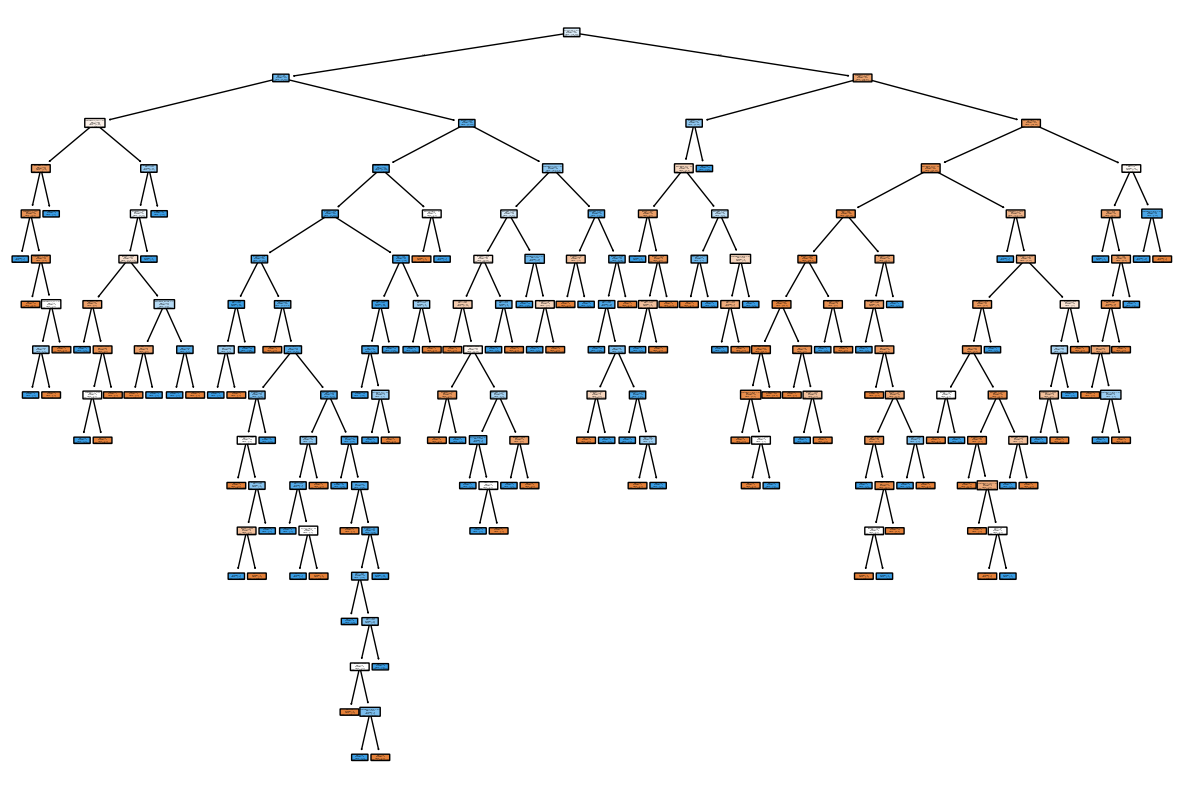

In [286]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)
y_pred = dt_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Decision Tree Model accuracy: {accuracy}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
plt.figure(figsize=(15, 10))
plot_tree(dt_model, filled=True, feature_names=X.columns, class_names=['No Heart Disease', 'Heart Disease'], rounded=True)
plt.show()



Top 10 Features Based on Importance:
              Feature  Importance
17        ST_Slope_Up    0.346483
3         Cholesterol    0.108789
7             Oldpeak    0.097920
5               MaxHR    0.092619
2           RestingBP    0.070657
0                 Age    0.055529
1                 Sex    0.054476
4           FastingBS    0.051689
8   ChestPainType_ASY    0.034610
6      ExerciseAngina    0.029051


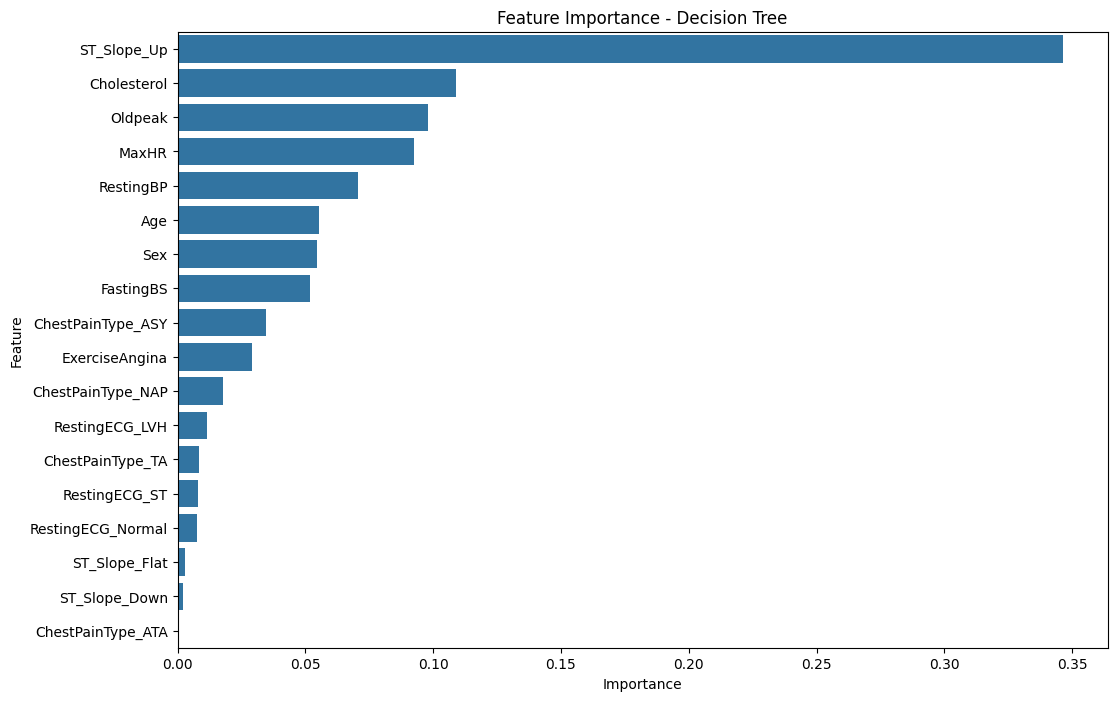

In [287]:
feature_importances = dt_model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': feature_importances
})
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print("\nTop 10 Features Based on Importance:")
print(feature_importance_df.head(10))
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title('Feature Importance - Decision Tree')
plt.show()

        PC1       PC2  HeartDisease
0 -1.442251 -1.540949             0
1 -2.329721  1.406463             1
2 -3.248755 -0.444572             0
3 -2.494127 -2.183328             1
4 -1.621146  0.992333             0


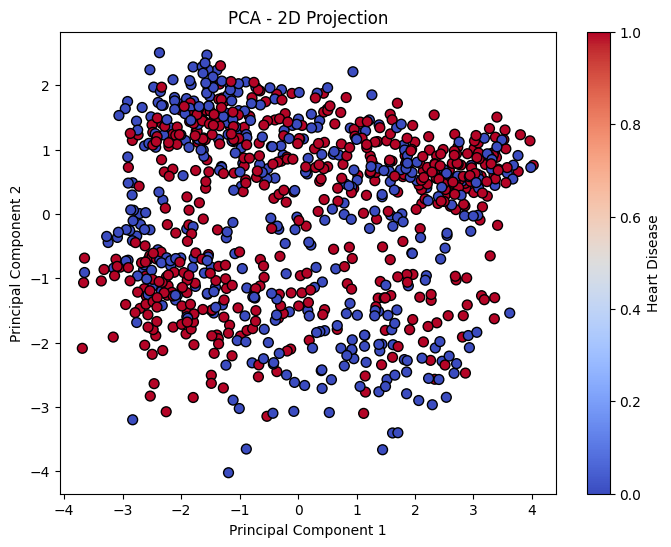


Explained Variance Ratio:
[0.2107086  0.10451998]


In [288]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
pca_df['HeartDisease'] = y
print(pca_df.head())
plt.figure(figsize=(8, 6))
plt.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df['HeartDisease'], cmap='coolwarm', edgecolor='k', s=50)
plt.title('PCA - 2D Projection')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Heart Disease')
plt.show()
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

Number of samples in each cluster for 2 clusters:
0    515
1    403
Name: count, dtype: int64


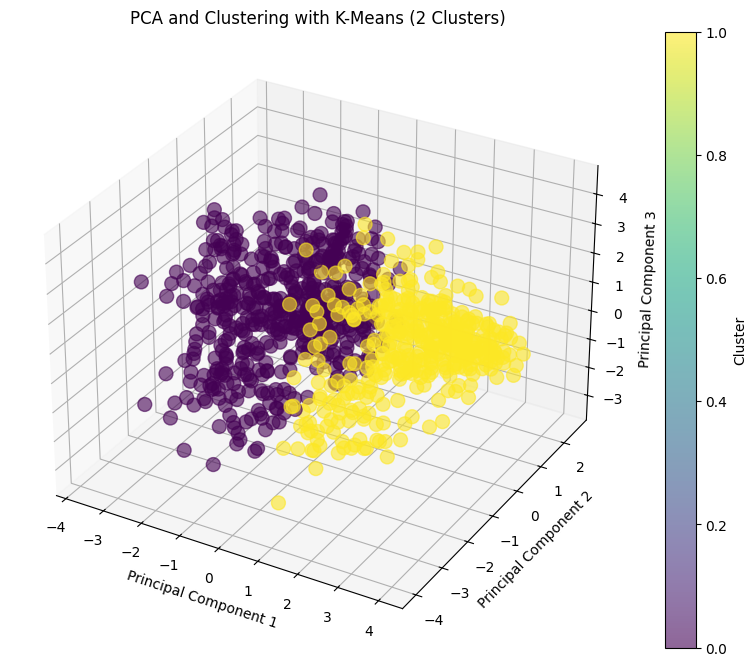


Explained Variance Ratio for 2 clusters:
[0.2107086  0.10451998 0.08688517]
Number of samples in each cluster for 3 clusters:
2    399
1    372
0    147
Name: count, dtype: int64


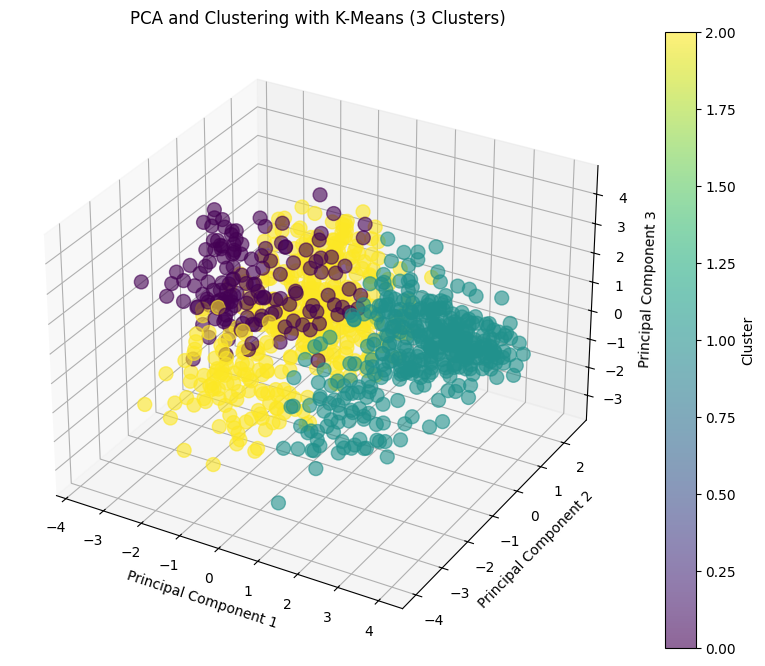


Explained Variance Ratio for 3 clusters:
[0.2107086  0.10451998 0.08688517]
Number of samples in each cluster for 4 clusters:
1    302
2    286
3    181
0    149
Name: count, dtype: int64


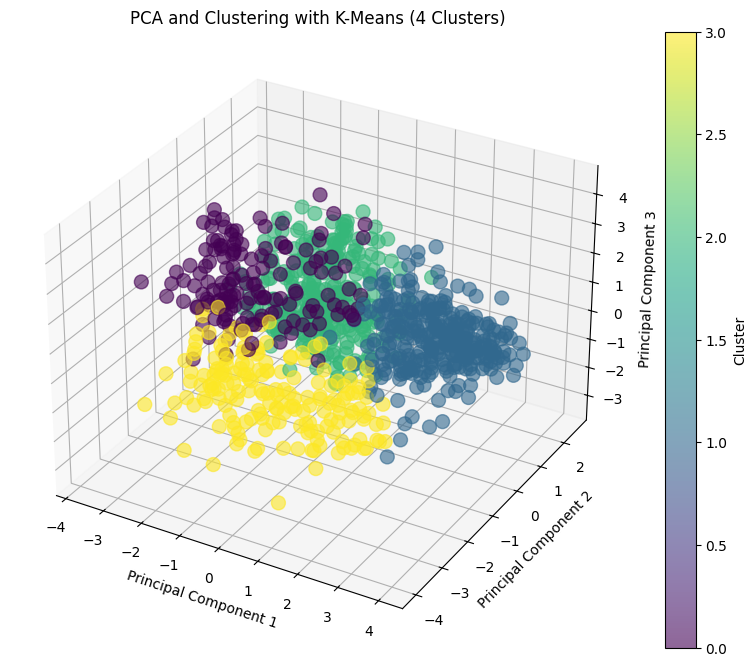


Explained Variance Ratio for 4 clusters:
[0.2107086  0.10451998 0.08688517]
Number of samples in each cluster for 5 clusters:
2    303
1    229
4    135
0    126
3    125
Name: count, dtype: int64


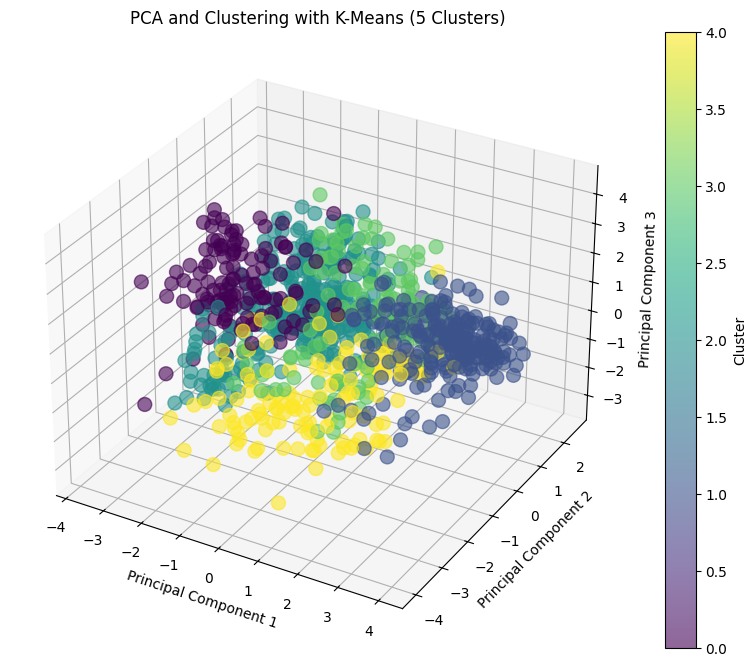


Explained Variance Ratio for 5 clusters:
[0.2107086  0.10451998 0.08688517]


In [294]:

cluster_range = [2, 3, 4, 5]  

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    kmeans.fit(X_scaled)
    X['Cluster'] = kmeans.labels_
    print(f"Number of samples in each cluster for {n_clusters} clusters:")
    print(pd.Series(kmeans.labels_).value_counts())
    pca = PCA(n_components=3)
    X_pca = pca.fit_transform(X_scaled)
    pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])
    pca_df['Cluster'] = kmeans.labels_
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(pca_df['PC1'], pca_df['PC2'], pca_df['PC3'], c=pca_df['Cluster'], cmap='viridis', s=100, alpha=0.6)
    ax.set_title(f'PCA and Clustering with K-Means ({n_clusters} Clusters)')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.set_zlabel('Principal Component 3')
    fig.colorbar(scatter, label='Cluster')
    plt.show()
    print(f"\nExplained Variance Ratio for {n_clusters} clusters:")
    print(pca.explained_variance_ratio_)



In [293]:
# Decision Tree Model
dt_model = DecisionTreeClassifier(random_state=42)  
dt_model.fit(X_train, y_train)  
y_pred_dt = dt_model.predict(X_test)  
accuracy_dt = accuracy_score(y_test, y_pred_dt)  

# Logistic Regression Model
log_reg_model = LogisticRegression(random_state=42)  
log_reg_model.fit(X_train, y_train)  
y_pred_log_reg = log_reg_model.predict(X_test)  
accuracy_log_reg = accuracy_score(y_test, y_pred_log_reg)  

# XGBoost Model
xgboost_model = xgb.XGBClassifier(random_state=42)  
xgboost_model.fit(X_train, y_train)  
y_pred_xgb = xgboost_model.predict(X_test)  
accuracy_xgb = accuracy_score(y_test, y_pred_xgb)  

# SVM Model
svm_model = SVC(random_state=42) 
svm_model.fit(X_train, y_train)  
y_pred_svm = svm_model.predict(X_test)  
accuracy_svm = accuracy_score(y_test, y_pred_svm)  

# Print model accuracies
print("Decision Tree Model Accuracy:", accuracy_dt)
print("Logistic Regression Model Accuracy:", accuracy_log_reg)
print("XGBoost Model Accuracy:", accuracy_xgb)
print("SVM Model Accuracy:", accuracy_svm)

# Classification Reports
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, y_pred_dt))
print("\nLogistic Regression Classification Report:")
print(classification_report(y_test, y_pred_log_reg))
print("\nXGBoost Classification Report:")
print(classification_report(y_test, y_pred_xgb))
print("\nSVM Classification Report:")
print(classification_report(y_test, y_pred_svm))



c:\Users\aaa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Decision Tree Model Accuracy: 0.8206521739130435
Logistic Regression Model Accuracy: 0.8804347826086957
XGBoost Model Accuracy: 0.8967391304347826
SVM Model Accuracy: 0.7119565217391305

Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.81      0.80        80
           1       0.85      0.83      0.84       104

    accuracy                           0.82       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.82      0.82      0.82       184


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86        80
           1       0.89      0.89      0.89       104

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184


XGBoost Classification Report:
              precision    recall  f1-score   


Decision Tree Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.81      0.80        80
           1       0.85      0.83      0.84       104

    accuracy                           0.82       184
   macro avg       0.82      0.82      0.82       184
weighted avg       0.82      0.82      0.82       184



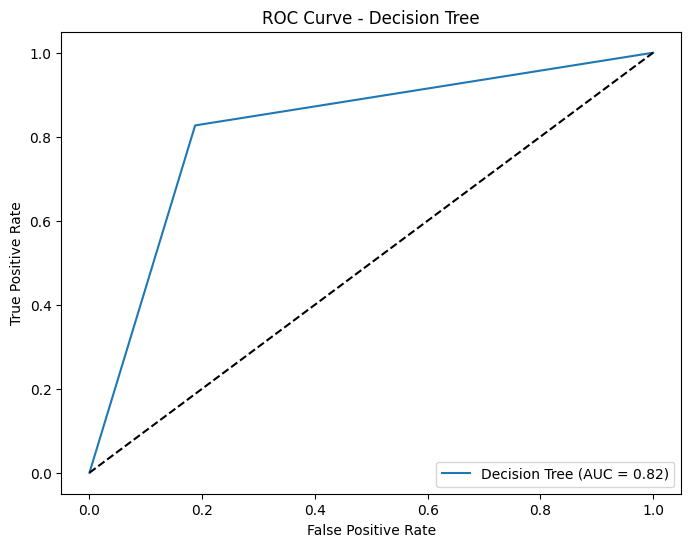


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86        80
           1       0.89      0.89      0.89       104

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



c:\Users\aaa\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


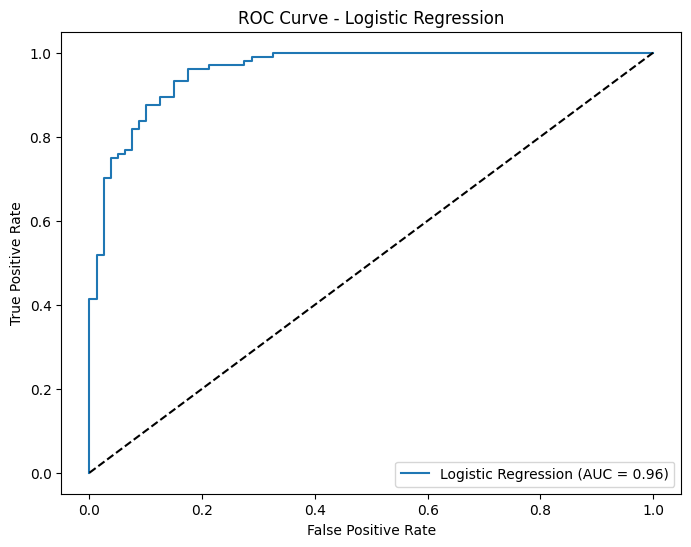


XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.88      0.88        80
           1       0.90      0.91      0.91       104

    accuracy                           0.90       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.90      0.90      0.90       184



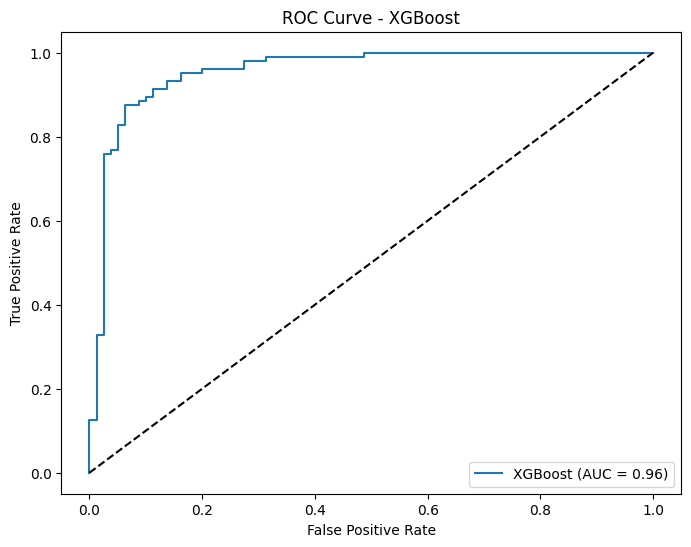


SVM Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.70      0.68        80
           1       0.76      0.72      0.74       104

    accuracy                           0.71       184
   macro avg       0.71      0.71      0.71       184
weighted avg       0.71      0.71      0.71       184



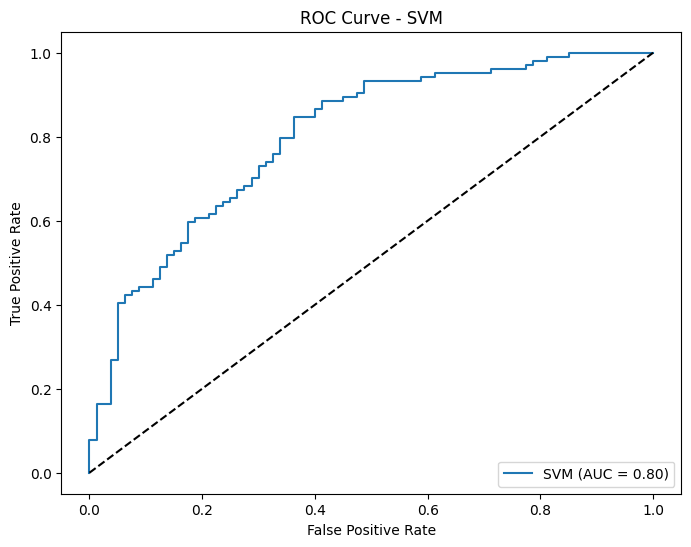


Comparison of Models:
                 Model  Accuracy  Precision    Recall  F1-Score       AUC  \
1  Logistic Regression  0.880435   0.894231  0.894231  0.894231  0.958293   
2              XGBoost  0.896739   0.904762  0.913462  0.909091  0.955769   
0        Decision Tree  0.820652   0.851485  0.826923  0.839024  0.819712   
3                  SVM  0.711957   0.757576  0.721154  0.738916  0.800361   

   Time (s)  
1  0.033550  
2  0.175062  
0  0.018749  
3  0.170386  

Best Model Based on AUC:
Model        Logistic Regression
Accuracy                0.880435
Precision               0.894231
Recall                  0.894231
F1-Score                0.894231
AUC                     0.958293
Time (s)                 0.03355
Name: 1, dtype: object


In [291]:

# Initialize models in a dictionary for easier iteration
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Logistic Regression": LogisticRegression(random_state=42),
    "XGBoost": xgb.XGBClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

# List to store the results of each model
results = []

# Iterate over each model to train and evaluate
for model_name, model in models.items():
    # Track the execution time for training and prediction
    start_time = time.time()
    
    # Train the model
    model.fit(X_train, y_train)
    
    # Predict using the trained model
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    # ROC Curve and AUC
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    auc_score = auc(fpr, tpr)

    # Calculate execution time
    exec_time = time.time() - start_time

    # Store the results in a dictionary and append to the results list
    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "AUC": auc_score,
        "Time (s)": exec_time
    })
    
    # Print Classification Report for each model
    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Plot ROC curve for each model
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, label=f'{model_name} (AUC = {auc_score:.2f})')
    plt.plot([0, 1], [0, 1], 'k--')  # Diagonal line for random predictions
    plt.title(f'ROC Curve - {model_name}')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(loc='lower right')
    plt.show()

# Create a DataFrame from the results list for comparison
results_df = pd.DataFrame(results)

# Display comparison of models sorted by AUC
print("\nComparison of Models:")
print(results_df.sort_values(by='AUC', ascending=False))

# Identify and display the best model based on AUC
best_model = results_df.iloc[results_df['AUC'].idxmax()]
print("\nBest Model Based on AUC:")
print(best_model)